# 03 — Are supervised patterns stable and useful?

**Question.** Check training-sample dependence, shoulder timing sensitivity and the final research interpretation.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/injury_supervised_reduction.yaml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.supervised_reduction import inputs,read_table,OUT
from src.injury_analysis.supervised_workflow import ensure_stage
from src.injury_analysis import supervised_plots as plots
FORCE_RECOMPUTE=False
a,events,spec,matches=inputs()
pd.set_option('display.max_columns',18)


## Component and model stability
Use 12 paired whole-pitcher training bootstraps for shoulder and lower body, in the original and combined representations. Refit imputation, scale, PLS/PCA and classifier each time. The original validation-selected count remains fixed; these diagnostics do not include dimension-reselection uncertainty.

Compare directions in the same original training units after adjusting for refitted scales. Absolute first-axis cosine removes arbitrary sign flips. Subspace overlap is sign/rotation invariant, but larger or full-rank subspaces are easier to reproduce and should not be directly compared as equivalent tasks. Report score ranks and top-5% alert-set overlap as separate predictive stability outcomes. Inspect the number of distinct positive training events retained in each draw.

Using verified prediction artifacts.


Using verified stability artifacts.


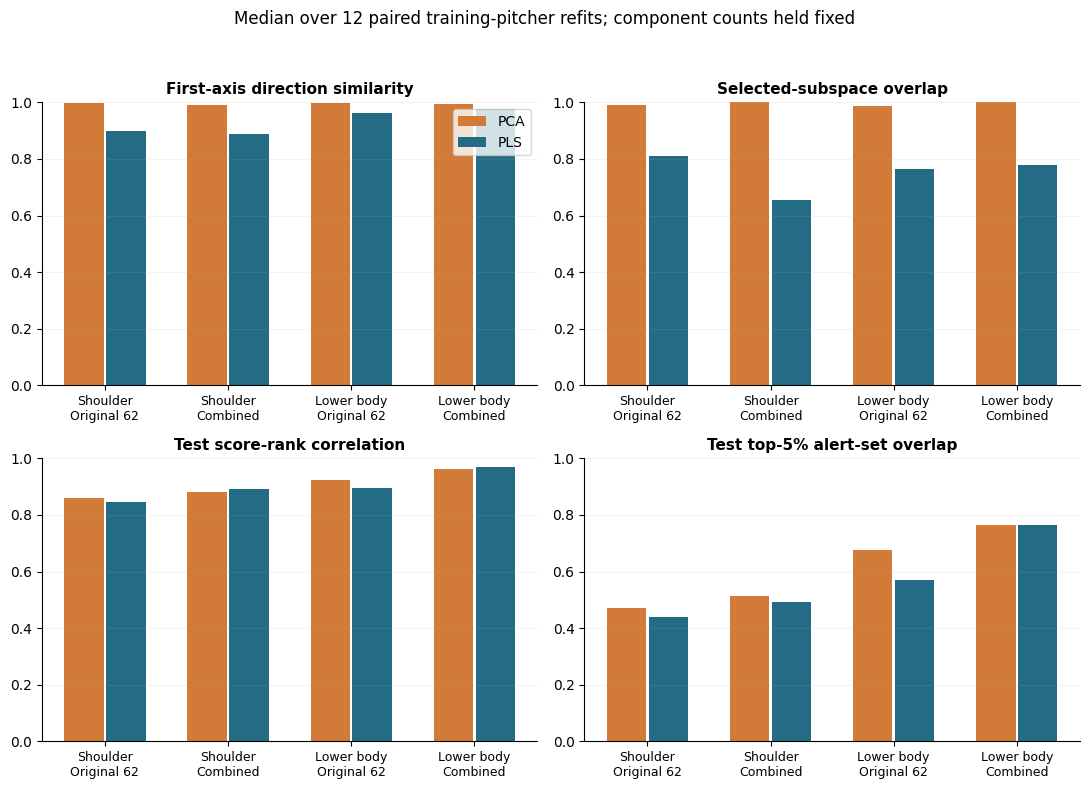

,category,block,method,partition,refits,mean_ap,sd_ap,median_rank_correlation,median_alert_jaccard,median_first_axis_cosine,min_first_axis_cosine,median_subspace_overlap
0,Lower body,Combined,PCA,test,12,0.046082,0.002180,0.961393,0.762894,0.992734,0.973840,1.000000
1,Lower body,Combined,PCA,validation,12,0.038259,0.000919,0.950832,0.684103,0.992734,0.973840,1.000000
2,Lower body,Combined,PLS,test,12,0.044977,0.002029,0.971120,0.765122,0.974820,0.949770,0.779537
3,Lower body,Combined,PLS,validation,12,0.038595,0.001250,0.963288,0.708102,0.974820,0.949770,0.779537
4,Lower body,Original 62,PCA,test,12,0.043589,0.001831,0.924747,0.674599,0.999011,0.996644,0.986969
5,Lower body,Original 62,PCA,validation,12,0.041028,0.002348,0.912268,0.646216,0.999011,0.996644,0.986969
6,Lower body,Original 62,PLS,test,12,0.046232,0.003451,0.896355,0.568836,0.962109,0.939358,0.765512
7,Lower body,Original 62,PLS,validation,12,0.044089,0.002234,0.884434,0.539513,0.962109,0.939358,0.765512
8,Shoulder,Combined,PCA,test,12,0.049488,0.004631,0.881312,0.514172,0.991831,0.981731,1.000000
9,Shoulder,Combined,PCA,validation,12,0.036116,0.002252,0.876592,0.502685,0.991831,0.981731,1.000000


mean       min       max
category   block       method family                                         
Lower body Combined    PCA    Current departure  0.001831  0.000446  0.003201
                              Prior profile      0.998169  0.996799  0.999554
                       PLS    Current departure  0.070437  0.023879  0.116988
                              Prior profile      0.929563  0.883012  0.976121
           Original 62 PCA    command            0.001585  0.001191  0.002038
                              extension          0.003234  0.002022  0.004709
                              pitch_mix          0.010344  0.006239  0.012992
                              pitcher_history    0.067223  0.060205  0.073011
                              release_mechanics  0.003684  0.001784  0.006715
                              spin_movement      0.002388  0.001362  0.004207
                              velocity           0.022258  0.013815  0.033438
                              workload           0.889284  0.867621  0.904602
                       PLS    command            0.028856  0.010321  0.051925
                              extension          0.010331  0.003036  0.024302
                              pitch_mix          0.015641  0.004818  0.039301
                              pitcher_history    0.480096  0.393597  0.590949
                              release_mechanics  0.024303  0.014443  0.046530
                              spin_movement      0.037165  0.027241  0.049504
                              velocity           0.141380  0.093087  0.191004
                              workload           0.262228  0.172837  0.367091
Shoulder   Combined    PCA    Current departure  0.002067  0.001013  0.003278
                              Prior profile      0.997933  0.996722  0.998987
                       PLS    Current departure  0.424989  0.325447  0.649062
                              Prior profile      0.575011  0.350938  0.674553
           Original 62 PCA    command            0.001526  0.000913  0.002142
                              extension          0.003410  0.002595  0.004593
                              pitch_mix          0.011491  0.007486  0.016153
                              pitcher_history    0.067988  0.061970  0.073380
                              release_mechanics  0.003104  0.001861  0.004651
                              spin_movement      0.002424  0.001194  0.003533
                              velocity           0.024850  0.018275  0.032657
                              workload           0.885207  0.877096  0.893823
                       PLS    command            0.124321  0.020301  0.206084
                              extension          0.025193  0.003740  0.061566
                              pitch_mix          0.026741  0.005894  0.056100
                              pitcher_history    0.117431  0.035149  0.242099
                              release_mechanics  0.058470  0.031180  0.098984
                              spin_movement      0.034901  0.008454  0.095761
                              velocity           0.319505  0.215566  0.395110
                              workload           0.293438  0.149584  0.477583

min  max
category   block                
Lower body Combined     220  252
           Original 62  220  252
Shoulder   Combined     210  240
           Original 62  210  240

In [2]:
ensure_stage('prediction',a,events,spec,matches,force=False)
ensure_stage('stability',a,events,spec,matches,force=FORCE_RECOMPUTE)
plots.stability_figure();plt.show()
display(read_table('stability_summary'))
display(read_table('refit_family_weights').groupby(['category','block','method','family']).first_axis_squared_weight.agg(['mean','min','max']))
display(read_table('training_refits').groupby(['category','block']).distinct_train_positive_events.agg(['min','max']))

## Focused shoulder sensitivity
The previous profile/departure analysis raised a specific concern: apparent gains may be concentrated just before the recorded event. Refit original, departure and combined representations after excluding final-six-day positive rows; never label those rows healthy. Separately require complete P+D measurement support, targeting the baseline/departure missingness concern without demanding that every original structural feature be observed.

For each sensitivity, both methods use the same rows, training-only transforms and validation-selected component counts. Changes across conditions therefore include changed samples and prevalence; interpret within-condition contrasts rather than raw AP differences across conditions.

In [3]:
ensure_stage('sensitivity',a,events,spec,matches,force=FORCE_RECOMPUTE)
display(read_table('sensitivity_selection'))
display(read_table('sensitivity_differences'))
display(read_table('sensitivity_performance')[[
 'analysis','block','partition','variant','rows','positive_rows','prevalence','average_precision','brier_score']])

Using verified sensitivity artifacts.


,category,block,condition,method,selected_components,continuous_features,passthrough_columns,design_columns,validation_ap,plateau_components,plateau_cutoff_ap,training_variance_retained,pca_variance_90_components,train_rows,train_positive_rows,train_positive_events
0,Shoulder,Original 62,Complete P+D measurements,PCA,31,60,21,52,0.038739,30,0.038169,0.909528,31,80929,2247,350
1,Shoulder,Original 62,Complete P+D measurements,PLS,30,60,21,51,0.045328,20,0.044429,0.780717,31,80929,2247,350
2,Shoulder,Departure,Complete P+D measurements,PCA,7,8,0,7,0.034939,7,0.034559,0.927517,7,80929,2247,350
3,Shoulder,Departure,Complete P+D measurements,PLS,1,8,0,1,0.035241,1,0.034846,0.132742,7,80929,2247,350
4,Shoulder,Combined,Complete P+D measurements,PCA,20,20,1,21,0.036949,1,0.036468,1.000000,16,80929,2247,350
5,Shoulder,Combined,Complete P+D measurements,PLS,2,20,1,3,0.038076,2,0.037539,0.114349,16,80929,2247,350
6,Shoulder,Original 62,Exclude final six days,PCA,30,60,47,77,0.022849,30,0.022722,0.900286,30,81340,1636,312
7,Shoulder,Original 62,Exclude final six days,PLS,1,60,47,48,0.023865,1,0.023688,0.046289,30,81340,1636,312
8,Shoulder,Departure,Exclude final six days,PCA,3,8,8,11,0.022960,3,0.022827,0.476525,7,81340,1636,312
9,Shoulder,Departure,Exclude final six days,PLS,1,8,8,9,0.022956,1,0.022824,0.129287,7,81340,1636,312


,category,partition,analysis,variant,reference,ap_difference,ap_low,ap_high,brier_difference,...,event_gained_events,event_lost_events,event_shared_detected_events,event_common_lead_mean,event_common_lead_low,event_common_lead_high,event_common_lead_events,event_common_lead_pitchers,block
0,Shoulder,validation,Complete P+D measurements,PLS selected,Unreduced,0.000242,-0.001450,0.001794,-5.567760e-06,...,1,2,23,0.956522,0.000000,3.087500,23,22,Original 62
1,Shoulder,validation,Complete P+D measurements,PLS selected,PCA selected,0.006589,0.000650,0.016777,-5.842200e-05,...,7,5,17,2.411765,-0.652941,4.916176,17,17,Original 62
2,Shoulder,test,Complete P+D measurements,PLS selected,Unreduced,-0.000132,-0.002051,0.001471,2.570433e-07,...,1,0,27,-0.074074,-0.230769,0.000000,27,24,Original 62
3,Shoulder,test,Complete P+D measurements,PLS selected,PCA selected,0.007173,0.000963,0.016732,-1.118775e-04,...,2,10,26,-0.423077,-2.760096,2.121267,26,23,Original 62
4,Shoulder,validation,Complete P+D measurements,PLS selected,Unreduced,0.000394,-0.000723,0.001605,-7.119938e-06,...,5,3,23,-0.173913,-0.521739,0.000000,23,23,Departure
5,Shoulder,validation,Complete P+D measurements,PLS selected,PCA selected,0.000303,-0.000788,0.001473,-6.151864e-06,...,5,2,23,-0.173913,-0.695652,0.000000,23,23,Departure
6,Shoulder,test,Complete P+D measurements,PLS selected,Unreduced,0.000447,-0.000898,0.001763,-3.467682e-06,...,5,6,24,-0.083333,-1.434783,1.038462,24,23,Departure
7,Shoulder,test,Complete P+D measurements,PLS selected,PCA selected,0.000366,-0.000962,0.001682,-2.826081e-06,...,5,6,24,-0.083333,-1.434783,1.038462,24,23,Departure
8,Shoulder,validation,Complete P+D measurements,PLS selected,Unreduced,0.001127,-0.000618,0.002672,-3.833101e-05,...,5,0,20,1.400000,0.050000,3.081250,20,20,Combined
9,Shoulder,validation,Complete P+D measurements,PLS selected,PCA selected,0.001127,-0.000618,0.002672,-3.833101e-05,...,5,0,20,1.400000,0.050000,3.081250,20,20,Combined


,analysis,block,partition,variant,rows,positive_rows,prevalence,average_precision,brier_score
0,Complete P+D measurements,Original 62,validation,Unreduced,26666,729,0.027338,0.045086,0.026552
1,Complete P+D measurements,Original 62,validation,Context/availability only,26666,729,0.027338,0.029750,0.026604
2,Complete P+D measurements,Original 62,validation,PCA selected,26666,729,0.027338,0.038739,0.026605
3,Complete P+D measurements,Original 62,validation,PLS selected,26666,729,0.027338,0.045328,0.026546
4,Complete P+D measurements,Original 62,test,Unreduced,27459,837,0.030482,0.055589,0.029315
5,Complete P+D measurements,Original 62,test,Context/availability only,27459,837,0.030482,0.033826,0.029555
6,Complete P+D measurements,Original 62,test,PCA selected,27459,837,0.030482,0.048284,0.029427
7,Complete P+D measurements,Original 62,test,PLS selected,27459,837,0.030482,0.055457,0.029315
8,Complete P+D measurements,Departure,validation,Unreduced,26666,729,0.027338,0.034847,0.026563
9,Complete P+D measurements,Departure,validation,Context/availability only,26666,729,0.027338,0.027338,0.026591


In [4]:
from src.injury_analysis.supervised_report import write_synthesis
display(Markdown(write_synthesis()))

# Supervised dimensionality reduction: findings

Supervision finds compact predictive directions in the **departure and combined profile/departure blocks**, but it does not establish a small universal injury signature. In the full feature representation, PLS usually preserves the original model’s performance and sometimes improves over PCA. It does not demonstrate a consistent new performance advantage over the original features.

## Comparison and model selection

PLS learns continuous-feature directions from the binary 30-day injury outcome in **training only**. An orthonormal basis for each nested PLS span feeds the same L2 logistic classifier as the original and PCA models. This removes arbitrary latent scaling from the L2 comparison. Binary context and training-observed missingness flags pass through unchanged for both projection methods. All imputers and scales fit on training only.

Train through 2021; validation 2022–2023; previously examined test 2024–2025. The original 60-day embargo, category risk sets, all-event warning denominators and case/control matching are retained. Candidate dimensions are identical for PLS and PCA within a block, including the training-learned PCA-90% count. Maximum validation AP selects k; test outcomes never choose it. A separate full-span numerical control checks the projection/regularization implementation.

| Injury group | PCA k | PLS k | Original test AP | PCA test AP | PLS test AP |
|---|---:|---:|---:|---:|---:|
| Elbow / UCL | 30 | 10 | 0.0426 | 0.0374 | 0.0466 |
| Shoulder | 30 | 30 | 0.0559 | 0.0484 | 0.0561 |
| Forearm | 20 | 20 | 0.0228 | 0.0143 | 0.0226 |
| Other arm | 10 | 10 | 0.0101 | 0.0129 | 0.0097 |
| Trunk / neck | 30 | 3 | 0.0273 | 0.0262 | 0.0255 |
| Lower body | 30 | 30 | 0.0482 | 0.0450 | 0.0490 |
| Hand / wrist | 30 | 10 | 0.0092 | 0.0327 | 0.0094 |

PLS test AP is higher than the unreduced comparator in 4/7 groups by point estimate, but **0/7 paired 95% intervals exclude zero on the positive side**. Against validation-selected PCA, PLS is higher in 4/7 groups, with positive intervals in 3/7: elbow/UCL, shoulder and lower body. Shoulder and lower body also have positive PLS-versus-PCA AP intervals in validation. Hand/wrist and other-arm test comparisons favor PCA; thus supervision is not uniformly better.

## Is the injury-related information more compressible?

In the full 60-continuous-feature space, selected PLS counts range from 3 to 30. The shoulder model selects 30 (20 first reaches 95% of its best validation AP gain over prevalence); lower body selects 30. Trunk/neck selects 3, but its test AP is lower than the original model. These patterns do not support a universal one- or two-component injury representation.

Compression is clearer when level and departure representations are separated. Shoulder departure selects **1 of 8** continuous axes, versus 7 for PCA, with test AP **0.0435 versus 0.0431** for unreduced departures. Shoulder combined selects **2 of 20** continuous axes, versus 20 for PCA, with test AP **0.0529 versus 0.0518** for the unreduced combined model. Those AP increments are uncertain; the main finding is preservation with compression.

**Latent count is not total model size.** The original representation retains 47 binary/missingness columns outside the projection: a 30-axis model has 77 design columns, compared with 107 in the unreduced model. The one-axis shoulder departure model still has 9 total columns; the two-axis combined model has 20. Context/availability-only comparisons and complete-measurement checks are saved. A binary linear classifier can ultimately produce a single decision score; compact prediction is not proof of a low-dimensional biological injury manifold.

The component curves and compression table report both the first tested count reaching 95% of the best validation **AP gain above prevalence** and whether all later tested counts remain above that threshold. This is a descriptive near-peak criterion, not a statistical plateau or an additional test-selected tuning rule. Curves can be irregular.

## What does supervision prioritize?

The first shoulder departure direction puts about **88% of its squared coefficient weight on velocity z-score**, with smaller release-Z, spin and zone-percentage contributions. Its training-score correlations with the earlier departure PCA components 2 and 3 have absolute values **0.60 and 0.52**. This reinforces part of the earlier shoulder pattern while showing that the supervised direction is primarily velocity departure, rather than a new complex physiological construct. Signs are oriented toward higher training injury outcome only for interpretation; native weights and correlations are retained.

In the first combined direction, squared weights are approximately **50% departure / 50% prior profile for shoulder**, **46% / 54% for elbow/UCL**, and **5% / 95% for lower body**. These are coordinate-weight summaries, not percentages of predictive performance or causal injury risk. PLS remains linear; mixing blocks does not test nonlinear interactions.

For shoulder, about **95%** of the first supervised profile score’s test variance is between pitchers, versus **10%** for the departure score and **70%** for the combined score. This preserves the distinction from the previous PCA/profile analysis: stable profile associations and within-pitcher variation are different inputs, and the combined predictor uses both.

## Timing, warning performance and robustness

The original out-of-training matches are reused. Common complete P+D support leaves 68 balanced shoulder pairs across five outings and 38 across all calendar bins. Shoulder departure PLS1 shows case/control separation, especially near the recorded event. Its last-minus-first separation change is about **+0.44 training-score SD** across outings, but the interval **−0.01 to +0.98** includes zero. Calendar change is also uncertain. Supervision therefore does not establish an earlier onset or a reliably earlier warning window than the preceding analyses.

Better AP need not improve the practical warning metric. For the full shoulder representation at a 5% outing alert budget, test 7–30-day event recall is **18.0% PLS, 23.0% PCA, 17.4% original**. PLS’s difference versus PCA is about **−5.0 percentage points** (paired interval approximately −9.8 to −0.3). Median warning lead among detected events is 16 days for PLS versus 21 for PCA; differing detected-event sets prevent treating that as a paired timing effect.

The shoulder complete-measurement sensitivity largely preserves the primary comparisons. Excluding final-six-day positive rows makes the full-representation PLS-versus-PCA AP gain small and uncertain. Some reduced-block test gains remain, but their validation counterparts are not consistently supported. These are targeted checks of the near-event concern raised by the prior analysis, not new independent confirmations.

Across 12 paired whole-pitcher training refits for shoulder and lower body, PLS leading directions are less stable than PCA directions. Shoulder first-axis absolute cosine is about 0.90 in the full block and 0.89 in the combined block, versus about 0.999 and 0.992 for PCA. Full-block PLS score ranks and alert sets are also less stable than PCA. Combined-block prediction stability is mixed. Report loading stability alongside performance; full-rank PCA subspaces are trivially stable, and subspace overlap is not directly comparable across different retained dimensions.

## Research interpretation

The evidence supports **category-specific, partly compact predictive structure**, particularly in within-pitcher departure measurements. It does not support a single compact injury mechanism or broad predictive improvement over the existing original-feature models. Shoulder contains the clearest departure direction; lower-body representation is much more profile dominated. Supervision helps choose useful combinations of measurements, but it does not convert associations with recorded IL/injury dates into evidence of biological susceptibility or short-term injury onset.

A sensible next step is to retain the one-axis shoulder departure and two-axis combined models as compact comparators, alongside original features and PCA, and freeze an explicit ≥7-day-warning evaluation in a new chronological period. Choose any alert-oriented tuning rule in training/validation before that evaluation. Do not replace the original pipeline on the basis of these exploratory results.

## Reproducibility and limits

The database, canonical injury events and every preceding report/notebook are preserved. The new [notebooks](../../notebooks/injury_supervised_reduction/README.md), [tables](tables/) and [PNG/PDF figures](figures/) include all categories, candidate curves, selected dimensions, paired AP/Brier/event differences, warning leads, loadings, PCA correlations, matched support, sensitivity results and training-refit diagnostics.

Evaluation bootstrap intervals condition on fitted models and selected dimensions; they do not include tuning uncertainty or adjust across every reported comparison. Validation selection makes validation performance optimistic. 2024–2025 has been examined repeatedly, and the small injury groups remain uncertain. Calibration/Brier values refer to the selected observed-follow-up cohort, not all MLB outings. Current measurements are available after a completed appearance. The “profile” means use at most 20 prior outings and are not immutable traits. Matching can retain cross-pair dependence when pitchers participate in more than one role.

PLS is implemented with the existing scikit-learn dependency; see the [official cross-decomposition guide](https://scikit-learn.org/1.9/modules/cross_decomposition.html). The implementation projects onto orthonormalized nested PLS spans and then uses logistic probabilities, rather than treating raw PLS regression outputs as calibrated probabilities.
